<a href="https://colab.research.google.com/github/zhiyuguo-innis/MSSP607/blob/main/WeeklyModules/Week12/PARTICIPATION_ACTIVITY_Week_12_Measure_a_p_value_from_a_t_test_on_a_data_set.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [9]:
import os
os.chdir('/content')
if not os.path.exists('/content/MSSP607'):
    !git clone https://github.com/zhiyuguo-innis/MSSP607.git
os.chdir('/content/MSSP607')
print(f"Changed directory to: {os.getcwd()}")

Changed directory to: /content/MSSP607


In [8]:
import pandas as pd
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('/content/MSSP607/data/Student Performance Data.csv')
print(df.shape)
df.head()

(1000, 10)


,gender,race/ethnicity,parental level of education,lunch,math score,reading score,writing score,total score,test preparation course,admission prospect
0,female,group B,bachelor's degree,standard,72,72,74,218,none,medium
1,female,group C,some college,standard,69,90,88,247,completed,high
2,female,group B,master's degree,standard,90,95,93,278,none,high
3,male,group A,associate's degree,free/reduced,47,57,44,148,none,low
4,male,group C,some college,standard,76,78,75,229,none,high


In [10]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats

# seaborn is a package for the visualization of statistical data
import seaborn as sns
sns.set(style='ticks')

##Example of a hypothesis test

##Adopted Source: Haslwanter, T. (2106, p.108). An introduction to statistics with Python. Springer, Switzerland.

The average newborn weight in the USA is 3.5kg, with a standard deviation of 0.76kg. Is a baby with a weight of 2.6kg significantly different from the population?

H0: The baby comes from a healthy population (i.e., there is no difference between the baby and the population.

Step:

1. Find the distribution of the healthy babies *u* = 3.5 and sigma = .76.

2. Calculate the CDF of the newborn (value of interests). CDF(2.6). The probability that the baby is .9kg or lighter.


In [11]:
from scipy import stats
# Create normal distribution
nd = stats.norm(3.5, 0.76)

In [12]:
#A 2.6 kg baby is not statistically significantly different from the population mean of 3.5 kg.
#We fail to reject H0, and accept that the difference between the baby and the populations is not statistically significant.
#significant since the p=0.118 at a 5% confidence level.

# One-tailed p-value (left tail)
x = 2.6 # Assign the specific value for the baby's weight
p_value = nd.cdf(x)  # OR stats.norm.cdf(z_score)
print(f'One-tailed p-value: {p_value:.6f}')

One-tailed p-value: 0.118165


In [13]:
alpha = 0.05
if p_value < alpha:
    print("Conclusion: Reject H0. The baby is significantly lighter than the population.")
else:
    print("Conclusion: Fail to reject H0. The baby's weight is not significantly low.")

Conclusion: Fail to reject H0. The baby's weight is not significantly low.


##Plots of Normality

QQ-Plots: The quantiles of a given data set

PP-Plots: The CDF of a given data set against the reference CDF

Probality Plots: Plot the ordered values of a given data set against the quintiles of the referenced distributions.

Text(0.5, 1.0, 'Shifted Normal Distribution')

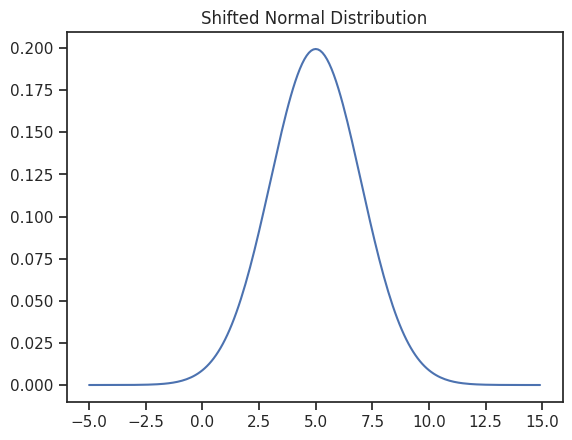

In [14]:
'''PDF, scatter plot, and histogram.'''
# Generate the data
x = np.arange(-5,15,0.1)
# Plot a normal distribution: "Probability density functions"
myMean = 5
mySD = 2
y = stats.norm(myMean, mySD).pdf(x)
plt.plot(x,y)
#A shifted normal distribution is simply a normal distribution whose mean has been shifted by adding or subtracting a constant.
plt.title('Shifted Normal Distribution')

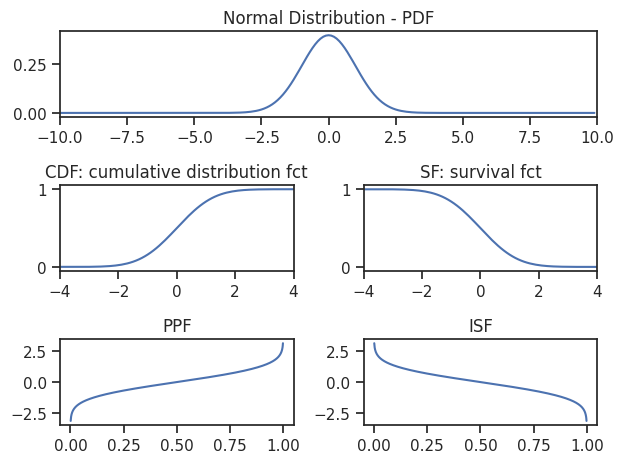

In [15]:
''' Different aspects of a normal distribution'''
# Generate the data
x = np.r_[-10:10:0.1]
rv = stats.norm(0,1)   # random variate

x2 = np.r_[0:1:0.001]

#A probability distribution function describes how probabilities are assigned to the possible values of a random variable.
#It tells you how likely each outcome is.
#A probability distribution function for a discrete random variable is called a probability mass function (PMF).
#A probability distribution function for a continuous random variable is called a probability density function (PDF).

ax = plt.subplot2grid((3,2),(0,0), colspan=2)
plt.plot(x,rv.pdf(x))
plt.xlim([-10,10])
plt.title('Normal Distribution - PDF')

plt.subplot(323)
plt.plot(x,rv.cdf(x))
plt.xlim([-4,4])
plt.title('CDF: cumulative distribution fct')

#In statistics and probability, the survival function of a random variable 𝑋 describes the probability that 𝑋
#takes a value greater than some threshold 𝑥.

plt.subplot(324)
plt.plot(x,rv.sf(x))
plt.xlim([-4,4])
plt.title('SF: survival fct')

#The Percent Point Function (PPF) is the inverse of the cumulative distribution function (CDF).

plt.subplot(325)
plt.plot(x2,rv.ppf(x2))
plt.title('PPF')

#The Inverse Survival Function (ISF) is the inverse of the survival function (SF) of a random variable.
plt.subplot(326)
plt.plot(x2,rv.isf(x2))
plt.title('ISF')
plt.tight_layout()
plt.show()

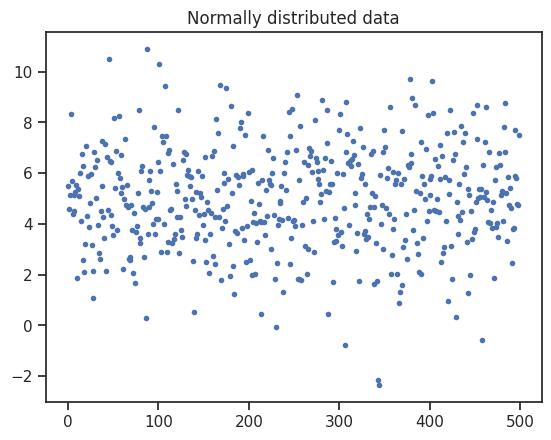

Text(0.5, 1.0, 'Histogram of normally distributed data')

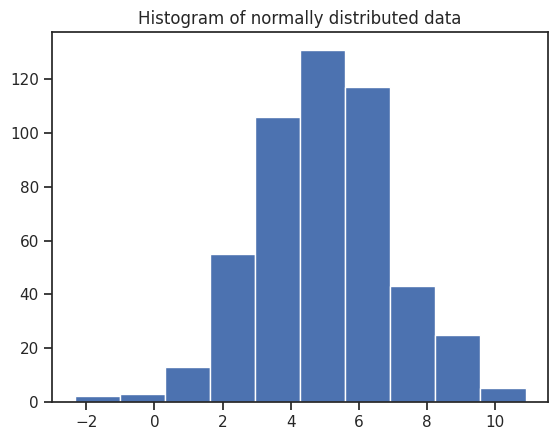

In [16]:
numData = 500
data = stats.norm.rvs(myMean, mySD, size = numData)
plt.plot(data, '.')
plt.title('Normally distributed data')
plt.show()

plt.hist(data)
plt.title('Histogram of normally distributed data')

(array([ 3.,  7., 16., 24., 26., 16.,  3.,  4.,  0.,  1.]),
 array([ 0.44206469,  1.59525848,  2.74845227,  3.90164606,  5.05483984,
         6.20803363,  7.36122742,  8.51442121,  9.66761499, 10.82080878,
        11.97400257]),
 <BarContainer object of 10 artists>)

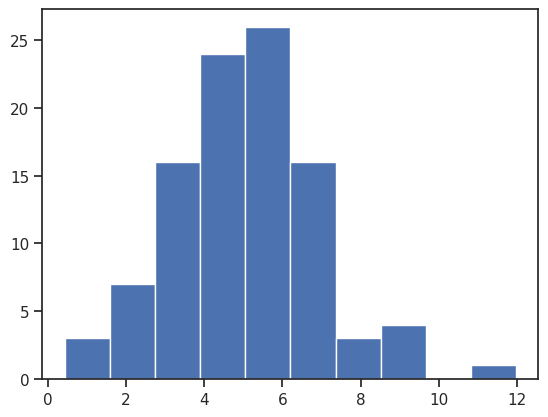

In [17]:
'''Check if the distribution is normal.'''
# Generate and show a distribution
numData = 100
data = stats.norm.rvs(myMean, mySD, size=numData)
plt.hist(data)

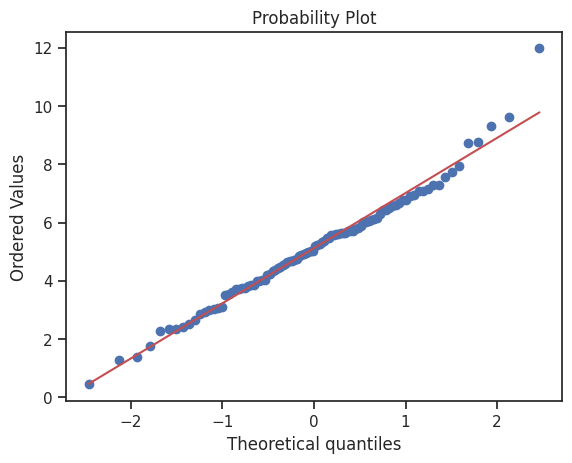

In [18]:
# Graphical test: if the data lie on a line, they are pretty much
# normally distributed
_ = stats.probplot(data, plot=plt)

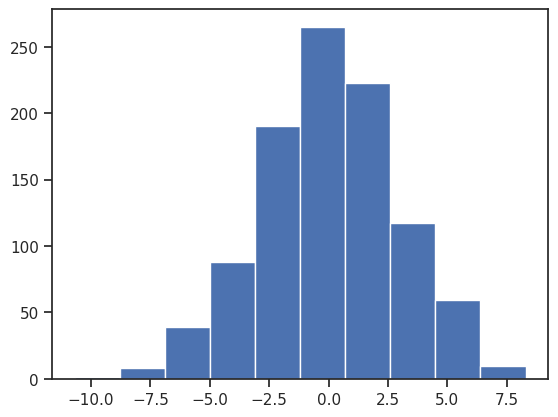

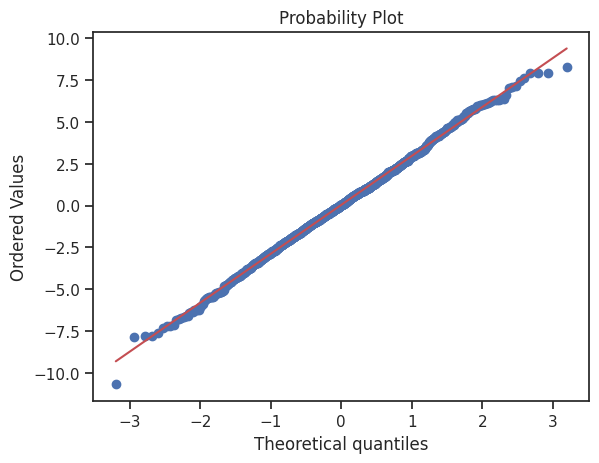

p-values for all 1000 data points: ----------------
Omnibus               0.913684
Shapiro-Wilk          0.556776
Lilliefors            0.671161
Kolmogorov-Smirnov    0.892921
dtype: float64
p-values for the first 100 data points: ----------------
Omnibus               0.656595
Shapiro-Wilk          0.920345
Lilliefors            0.300038
Kolmogorov-Smirnov    0.708685
dtype: float64
Data are normally distributed
Done!input('Done!')


In [19]:
"""
Graphical and quantitative check, if a given distribution is normal.
- For small sample-numbers (<50), you should use the Shapiro-Wilk test or the
    "normaltest"
- for intermediate sample numbers, the Lilliefors-test is good since the
    original Kolmogorov-Smirnov-test is unreliable when mean and std of the
    distribution are not known.
- the Kolmogorov-Smirnov(Kolmogorov-Smirnov) test should only be used for
    large sample numbers (>300)
"""

# author: Thomas Haslwanter, date: Feb-2021

# Import standard packages
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats
import pandas as pd

# additional packages
from statsmodels.stats.diagnostic import lilliefors
from typing import List


def generate_data(show_flag:bool=True) -> np.ndarray:
    """Generates input data for the function 'check_normality'

    Parameters
    show_flag : Controls the display of the generated data


    Returns
    -------
    data : vector with random data
    """

    # Set the parameters
    numData = 1000
    myMean = 0
    mySD = 3

    # To get reproducable values, I provide a seed value
    np.random.seed(1234)

    # Generate and show random data
    data = stats.norm.rvs(myMean, mySD, size=numData)

    if show_flag:
        plt.hist(data)
        plt.show()

    return data


def check_normality(data: np.ndarray, show_flag: bool=True) -> List[float]:
    """Check if the distribution is normal

    Parameters
    ----------
    data : vector of data to be tested
    show_flag : controls the display of data

    Returns
    -------
    ps : List of p-values for different normality tests
    """

    few_data = data[::10]

    # --- >>> START stats <<< ---
    # Graphical test: if the data lie on a line, they are pretty much
    # normally distributed
    if show_flag:
        _ = stats.probplot(data, plot=plt)
        plt.show()

    pVals = pd.Series()
    pFewVals = pd.Series()
    # The scipy normaltest is based on D-Agostino and Pearsons test that
    # combines skew and kurtosis to produce an omnibus test of normality.
    _, pVals['Omnibus']    = stats.normaltest(data)
    _, pFewVals['Omnibus'] = stats.normaltest(few_data)

    # Shapiro-Wilk test
    _, pVals['Shapiro-Wilk']    = stats.shapiro(data)
    _, pFewVals['Shapiro-Wilk'] = stats.shapiro(few_data)

    # Or you can check for normality with Lilliefors-test
    _, pVals['Lilliefors']    = lilliefors(data)
    _, pFewVals['Lilliefors'] = lilliefors(few_data)

    # Alternatively with original Kolmogorov-Smirnov test
    _, pVals['Kolmogorov-Smirnov']    = \
            stats.kstest((data-np.mean(data))/np.std(data,ddof=1), 'norm')
    _, pFewVals['Kolmogorov-Smirnov'] = \
        stats.kstest((few_data-np.mean(few_data))/np.std(few_data,ddof=1), 'norm')

    print(f'p-values for all {len(data)} data points: ----------------')
    print(pVals)
    print('p-values for the first 100 data points: ----------------')
    print(pFewVals)

    if pVals['Omnibus'] > 0.05:
        print('Data are normally distributed')
    # --- >>> STOP stats <<< ---

    return pVals


if __name__ == '__main__':

    data = generate_data()
    ps = check_normality(data)
    input('Done!')



##Hypothesis Test: Concepts, Errors, p-Value, and Sample Size

Example: You are an instructor, and the target score for students on their final exam is 110. Your contract depends on thier score not being significantly differrent that the target.

Final exam scores: 109.4, 76.2, 128.7, 93.7, 85.6, 117.7, 117.2, 87.3, 100.3, 55.11.

In [20]:
scores = np.array([[109.4, 76.2, 128.7, 93.7, 85.6, 117.7, 117.2, 87.3, 100.3, 55.11]])

##Hypothesis Test: Concepts, Errors, p-Value, and Sample Size

Example: You are an instructor, and the target score for studetsn on their final exam is 110. Your contract depends on thier score not being significantly differrent that the target.

Final exam scores: 109.4, 76.2, 128.7, 93.7, 85.6, 117.7, 117.2, 87.3, 100.3, 55.11.

In [21]:
import numpy as np
scores = np.array([109.4, 76.2, 128.7, 93.7, 85.6, 117.7, 117.2, 87.3, 100.3, 55.11])

In [22]:
stats.normaltest(scores) #scores are normally distributed.

NormaltestResult(statistic=np.float64(0.47578029290229346), pvalue=np.float64(0.7882892827127141))

In [23]:
np.mean(scores)

np.float64(97.121)

In [24]:
#differrence between the sample mean and the comparative score of 100
np.mean(scores) - 110

np.float64(-12.879000000000005)

In [25]:
#using the t-distributions (a distribution that depednds on the ratio of the sample mean and the standard error)
tval = (110 - np.mean(scores))/stats.sem(scores)
tval

np.float64(1.8360566316049283)

In [26]:
td = stats.t(len(scores)-1)
p= 2*td.sf(tval)
p  #the p value

np.float64(0.0995334338161495)

## Participation Activity Week 12: t-tests on the Student Performance Data Set

**Question 1:** Is there a statistically significant difference between males who completed the test preparation course and others?

I test this two ways, because "others" can mean two things:
- **(a)** males who completed the prep course vs. males who did not (holds gender constant, so it isolates the prep course), and
- **(b)** males who completed the prep course vs. everyone else in the data set (females + males without prep).

I use Welch's two-sample t-test (`equal_var=False`), which doesn't assume the two groups have equal variances. α = 0.05.

In [29]:
import pandas as pd
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns
# Adjust the path if the CSV is stored somewhere else in your Drive / repo
df = pd.read_csv('/content/MSSP607/data/Student Performance Data.csv')
print(df.shape)
df.head()

(1000, 10)


,gender,race/ethnicity,parental level of education,lunch,math score,reading score,writing score,total score,test preparation course,admission prospect
0,female,group B,bachelor's degree,standard,72,72,74,218,none,medium
1,female,group C,some college,standard,69,90,88,247,completed,high
2,female,group B,master's degree,standard,90,95,93,278,none,high
3,male,group A,associate's degree,free/reduced,47,57,44,148,none,low
4,male,group C,some college,standard,76,78,75,229,none,high


In [30]:
# Group sizes
pd.crosstab(df['gender'], df['test preparation course'], margins=True)

test preparation course,completed,none,All
gender,,,
female,184,334,518
male,174,308,482
All,358,642,1000


In [31]:
score_cols = ['math score', 'reading score', 'writing score', 'total score']
alpha = 0.05

def compare(group1, group2, label1, label2):
    """Welch t-test on every score column; returns a summary table."""
    rows = []
    for col in score_cols:
        a, b = group1[col], group2[col]
        t, p = stats.ttest_ind(a, b, equal_var=False)
        d = (a.mean() - b.mean()) / np.sqrt((a.var() + b.var()) / 2)   # Cohen's d (effect size)
        rows.append({'score': col,
                     f'mean {label1}': round(a.mean(), 2),
                     f'mean {label2}': round(b.mean(), 2),
                     'difference': round(a.mean() - b.mean(), 2),
                     't': round(t, 2),
                     'p-value': f'{p:.2e}',
                     "Cohen's d": round(d, 2),
                     'significant (p<0.05)': p < alpha})
    return pd.DataFrame(rows)

### (a) Males with prep course vs. males without prep course
H0: mean score of males who completed the prep course = mean score of males who did not.

In [32]:
male = df[df['gender'] == 'male']
male_prep = male[male['test preparation course'] == 'completed']
male_noprep = male[male['test preparation course'] == 'none']
print(f'Males with prep: n = {len(male_prep)},  males without prep: n = {len(male_noprep)}')

compare(male_prep, male_noprep, 'male prep', 'male no prep')

Males with prep: n = 174,  males without prep: n = 308


,score,mean male prep,mean male no prep,difference,t,p-value,Cohen's d,significant (p<0.05)
0,math score,72.34,66.69,5.65,4.21,3.27e-05,0.40,True
1,reading score,70.21,62.80,7.42,5.77,1.77e-08,0.55,True
2,writing score,69.79,59.65,10.14,8.14,6.23e-15,0.77,True
3,total score,212.34,189.13,23.21,6.18,1.73e-09,0.59,True


In [33]:
# Check the normality assumption on the total score (the t-test is also robust here because n > 150 per group)
print('Normaltest, male prep   :', stats.normaltest(male_prep['total score']))
print('Normaltest, male no prep:', stats.normaltest(male_noprep['total score']))

# Non-parametric check that doesn't assume normality
print('Mann-Whitney U (total)  :', stats.mannwhitneyu(male_prep['total score'], male_noprep['total score']))

Normaltest, male prep   : NormaltestResult(statistic=np.float64(5.186330099648431), pvalue=np.float64(0.07478297328266548))
Normaltest, male no prep: NormaltestResult(statistic=np.float64(2.486524194277204), pvalue=np.float64(0.28844175654581156))
Mann-Whitney U (total)  : MannwhitneyuResult(statistic=np.float64(35241.5), pvalue=np.float64(8.912633458075488e-09))


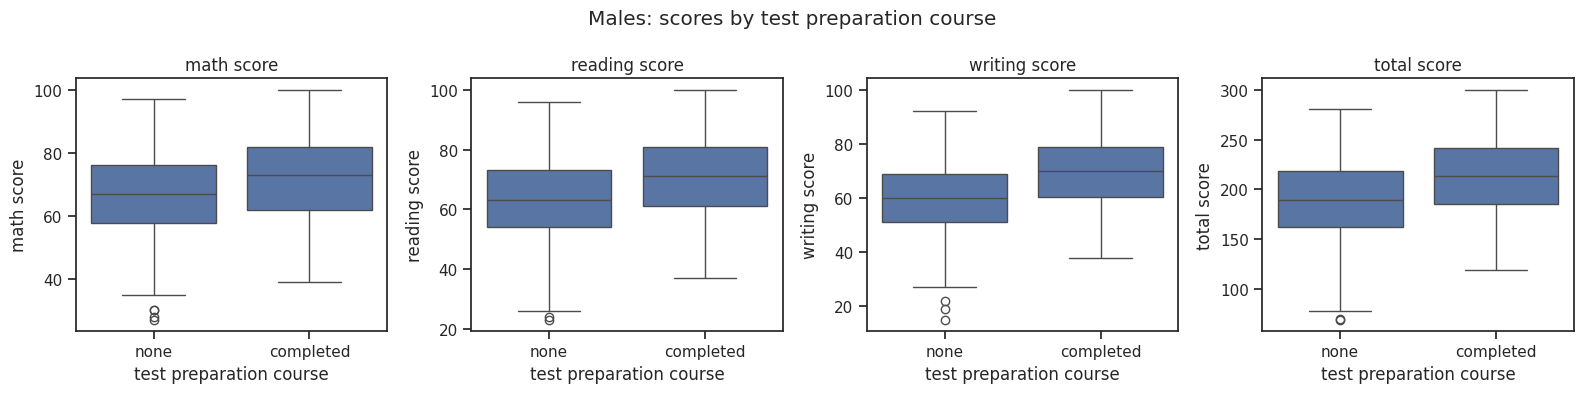

In [34]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, col in zip(axes, score_cols):
    sns.boxplot(data=male, x='test preparation course', y=col, ax=ax, order=['none', 'completed'])
    ax.set_title(col)
fig.suptitle('Males: scores by test preparation course')
plt.tight_layout()
plt.show()

### (b) Males with prep course vs. all other students
H0: mean score of males who completed the prep course = mean score of all other students.

In [35]:
is_male_prep = (df['gender'] == 'male') & (df['test preparation course'] == 'completed')
others = df[~is_male_prep]
print(f'Males with prep: n = {is_male_prep.sum()},  all others: n = {len(others)}')

compare(df[is_male_prep], others, 'male prep', 'others')

Males with prep: n = 174,  all others: n = 826


,score,mean male prep,mean others,difference,t,p-value,Cohen's d,significant (p<0.05)
0,math score,72.34,64.77,7.57,6.31,1.16e-09,0.52,True
1,reading score,70.21,68.95,1.26,1.09,2.76e-01,0.09,False
2,writing score,69.79,67.69,2.11,1.87,6.22e-02,0.15,False
3,total score,212.34,201.41,10.94,3.26,1.27e-03,0.26,True


### Answer to Question 1

**(a) Yes.** Males who completed the prep course scored significantly higher than males who did not on every subject: math (+5.7 points, p ≈ 3e-05), reading (+7.4, p ≈ 2e-08), writing (+10.1, p ≈ 6e-15) and total (+23.2, p ≈ 2e-09). We reject H0. The effect is moderate (Cohen's d ≈ 0.4–0.8) and largest for writing. Total scores pass the normality check and the Mann-Whitney U test agrees, so the result doesn't depend on the normality assumption.

**(b) Partly.** Compared with *all* other students, males with prep are significantly higher in math (p ≈ 1e-09) and total score (p ≈ 0.001), but **not** in reading (p ≈ 0.28) or writing (p ≈ 0.06). This comparison is muddied by gender: the "others" group is mostly females, who score higher in reading and writing (see below), which offsets the prep-course advantage. That is why (a) is the cleaner test of the prep course.

**Caveat:** this is observational data. Students chose whether to take the course, so the difference shows association, not proof that the course *caused* higher scores (e.g., more motivated students may be more likely to enroll).

## Question 2: Other differences of interest

In [36]:
# Does the prep course matter for females too?
female = df[df['gender'] == 'female']
compare(female[female['test preparation course'] == 'completed'],
        female[female['test preparation course'] == 'none'], 'female prep', 'female no prep')

,score,mean female prep,mean female no prep,difference,t,p-value,Cohen's d,significant (p<0.05)
0,math score,67.20,61.67,5.52,4.06,5.87e-05,0.37,True
1,reading score,77.38,69.98,7.39,6.01,4.02e-09,0.54,True
2,writing score,78.79,68.98,9.81,8.04,8.25e-15,0.72,True
3,total score,223.36,200.63,22.73,6.13,2.03e-09,0.55,True


In [37]:
# Gender differences (all students)
compare(female, male, 'female', 'male')

,score,mean female,mean male,difference,t,p-value,Cohen's d,significant (p<0.05)
0,math score,63.63,68.73,-5.10,-5.40,8.42e-08,-0.34,True
1,reading score,72.61,65.47,7.14,7.97,4.38e-15,0.50,True
2,writing score,72.47,63.31,9.16,10.00,1.71e-22,0.63,True
3,total score,208.71,197.51,11.20,4.18,3.19e-05,0.26,True


In [38]:
# Lunch type (standard vs. free/reduced) -- a rough proxy for family income
compare(df[df['lunch'] == 'standard'], df[df['lunch'] == 'free/reduced'], 'standard lunch', 'free/reduced lunch')

,score,mean standard lunch,mean free/reduced lunch,difference,t,p-value,Cohen's d,significant (p<0.05)
0,math score,70.03,58.92,11.11,11.48,5.54e-28,0.77,True
1,reading score,71.65,64.65,7.00,7.29,8.42e-13,0.49,True
2,writing score,70.82,63.02,7.80,7.84,1.72e-14,0.52,True
3,total score,212.51,186.60,25.91,9.32,1.58e-19,0.62,True


In [39]:
# More than two groups -> one-way ANOVA instead of a t-test
for col in ['race/ethnicity', 'parental level of education']:
    groups = [g['total score'] for _, g in df.groupby(col)]
    F, p = stats.f_oneway(*groups)
    print(f'{col}: F = {F:.2f}, p = {p:.2e}')
    print(df.groupby(col)['total score'].mean().round(1).sort_values().to_string(), '\n')

race/ethnicity: F = 9.10, p = 3.23e-07
race/ethnicity
group A    189.0
group B    196.4
group C    201.4
group D    207.5
group E    218.3 

parental level of education: F = 10.75, p = 4.38e-10
parental level of education
high school           189.3
some high school      195.3
some college          205.4
associate's degree    208.7
bachelor's degree     215.8
master's degree       220.8 



### Answer to Question 2

- **The prep-course effect is about the same for females** (+22.7 total points, p ≈ 2e-09) as for males (+23.2). The course is associated with higher scores for both genders, again most strongly in writing.
- **Gender:** males score significantly higher in math (68.7 vs 63.6, p ≈ 8e-08), while females score significantly higher in reading (72.6 vs 65.5) and writing (72.5 vs 63.3), both p < 1e-14. The gaps point in opposite directions by subject.
- **Lunch type shows the largest math gap in the data:** students with standard lunch score about 11 points higher in math than students on free/reduced lunch (p ≈ 6e-28, d ≈ 0.77), and about 26 points higher in total. If lunch status reflects family income, socioeconomic background is associated with scores at least as strongly as the prep course.
- **Race/ethnicity group** (ANOVA p ≈ 3e-07) and **parental education** also show significant differences in total score. Mean totals rise from group A (189) to group E (218), and from parents with a high-school education (189) to a master's degree (221).

These are all associations. A natural next step would be a regression with prep course, gender, and lunch together, to see whether the prep effect holds once the other factors are controlled for.